# PredictIQ — Exploratory Data Analysis & Statistical Investigation

**Dataset:** IBM Telco Customer Churn  
**Phase:** Phase 2: Dataset Acquisition, Validation & Exploratory Data Analysis  
**Objective:** Conduct an end-to-end, reproducible exploratory analysis of customer churn dynamics, validate schema and data constraints, test explicit statistical hypotheses, and document actionable business intelligence without model leakage.

---
## Methodological Principles
1. **Zero Data Leakage:** This phase focuses exclusively on discovery, data validation, and descriptive/inferential statistics. No predictive modeling or supervised feature fitting is conducted.
2. **Evidence-Based Insights:** All assertions are grounded in numerical distributions, formal hypothesis testing ($\chi^2$ and two-sample Welch t-tests), and effect size measures (Cramér's $V$, Cohen's $d$).
3. **Correlation vs. Causation:** We strictly distinguish statistical association from causal mechanism and identify potential confounding variables (e.g. Fiber Optic pricing vs. contract duration).

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Ensure project src is importable
project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(project_root / "src") not in sys.path:
    sys.path.insert(0, str(project_root / "src"))

from predictiq.config import get_config
from predictiq.data.validation import validate_dataset
from predictiq.data.cleaning import clean_telco_churn_data

# Visual styling configuration
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

config = get_config()
print(f"PredictIQ Environment: {config.environment} | Data Root: {config.paths.data_dir}")

PredictIQ Environment: development | Data Root: D:\Projects\PredictIQ\data


## 1. Raw Dataset Ingestion & Validation Audit

We begin by reading the raw immutable CSV file from `data/raw/` and running the PredictIQ automated validation engine to audit schema completeness, data types, duplicate identifiers, and boundary constraints.

In [2]:
raw_file = config.paths.raw_data_dir / "Telco-Customer-Churn.csv"
print(f"Inspecting raw file at: {raw_file}")

# Run validation engine
validation_report = validate_dataset(raw_file)
print(validation_report.summary())
print("\n" + validation_report.to_markdown())

Inspecting raw file at: D:\Projects\PredictIQ\data\raw\Telco-Customer-Churn.csv
ValidationReport(PASSED): 7043 rows, 21 columns, 1 issues detected (0 critical)

# PredictIQ Dataset Validation Report

- **Status:** VALID
- **Shape:** 7,043 rows × 21 columns
- **Duplicates:** 0 duplicate IDs

## Target Distribution
| Class | Count | Proportion |
|---|---|---|
| No | 5,174 | 73.46% |
| Yes | 1,869 | 26.54% |

## Data Quality Issues & Recommendations
| Severity | Rule | Column | Description | Count | Recommended Action |
|---|---|---|---|---|---|
| **INFO** | `WHITESPACE_AS_NULL` | `TotalCharges` | Column 'TotalCharges' has 11 blank/whitespace-only values. | 11 | Impute TotalCharges = 0.0 for tenure=0 new accounts. |


### Validation Audit Interpretation
- **Integrity:** The dataset contains 7,043 rows and 21 columns with **0 duplicate customer IDs**.
- **Schema:** All 21 required columns are present with no unexpected columns.
- **Data Quality Finding (`WHITESPACE_AS_NULL`):** Exactly **11 rows** in `TotalCharges` contain blank whitespace strings `" "`. As audited below, these 11 rows correspond precisely to new customers with `tenure == 0` months who have not yet completed their first billing cycle. None of these customers have churned.

In [3]:
# Load raw dataset and inspect the 11 blank TotalCharges records
raw_df = pd.read_csv(raw_file)
blank_total_charges = raw_df[raw_df["TotalCharges"].astype(str).str.strip() == ""]
print(f"Count of blank TotalCharges records: {len(blank_total_charges)}")
display(blank_total_charges[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]].head(5))

# Clean dataset via PredictIQ cleaning pipeline
df, cleaning_actions = clean_telco_churn_data(raw_df, impute_total_charges=True)
print("Cleaning actions completed:", cleaning_actions)
print(f"Post-cleaning null count in TotalCharges: {df['TotalCharges'].isna().sum()}")

Count of blank TotalCharges records: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No


Cleaning actions completed: {'original_rows': 7043, 'total_charges_imputed_count': 11, 'types_converted': {'TotalCharges': 'float64', 'tenure': 'int64', 'MonthlyCharges': 'float64', 'SeniorCitizen': 'int64'}, 'added_columns': ['tenure_cohort']}
Post-cleaning null count in TotalCharges: 0


## 2. Target Variable Analysis (Churn Distribution)

Next, we examine the primary target variable `Churn` to assess the overall churn rate and quantify the class balance.

,Count,Percentage (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


C:\Users\mkshi\AppData\Local\Temp\ipykernel_25684\3862974.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Churn", palette=palette, ax=axes[0])


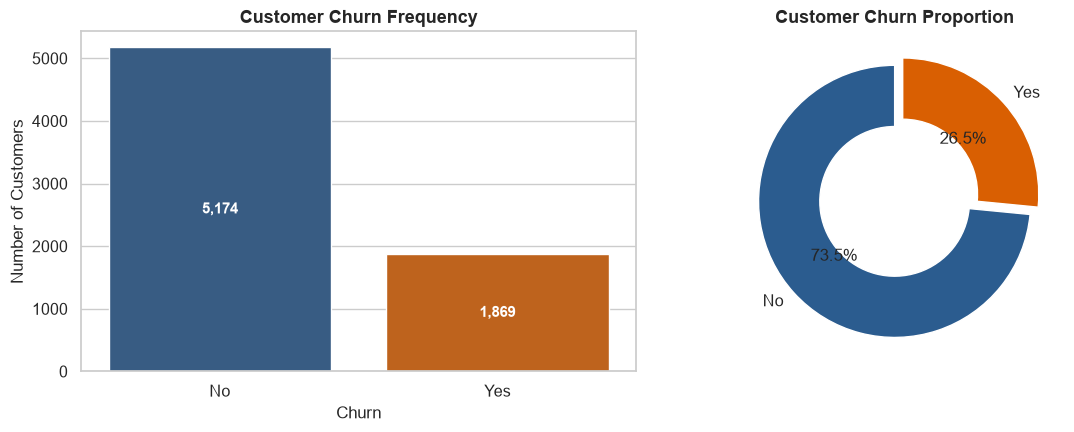

In [4]:
churn_counts = df["Churn"].value_counts()
churn_props = df["Churn"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Count": churn_counts,
    "Percentage (%)": churn_props.round(2)
})
display(target_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Bar chart of counts
palette = {"No": "#2b5c8f", "Yes": "#d95f02"}
sns.countplot(data=df, x="Churn", palette=palette, ax=axes[0])
axes[0].set_title("Customer Churn Frequency", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Number of Customers")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Donut chart of proportions
axes[1].pie(churn_props, labels=churn_props.index, autopct='%1.1f%%', startangle=90,
           colors=[palette["No"], palette["Yes"]], explode=(0, 0.08),
           wedgeprops=dict(width=0.45, edgecolor='white'))
axes[1].set_title("Customer Churn Proportion", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

### Target Distribution Findings
- **Churn Rate:** **26.54%** (1,869 customers churned, 5,174 retained).
- **Class Imbalance:** The target exhibits an approximate **3:1 majority-to-minority ratio**.
- **Modeling Implication for Future Phases:** Standard accuracy would yield an inflated ~73.5% naive baseline (predicting all "No"). Downstream modeling must evaluate PR-AUC (Precision-Recall AUC), ROC-AUC, and F1-score rather than naive accuracy.

## 3. Demographic & Customer Profile Dimensions

We evaluate whether churn dynamics vary systematically by demographic attributes: `gender`, `SeniorCitizen`, `Partner`, and `Dependents`.

C:\Users\mkshi\AppData\Local\Temp\ipykernel_25684\3127619207.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=churn_by_demo, x=col, y="ChurnRate", ax=ax, palette="Blues_r")
C:\Users\mkshi\AppData\Local\Temp\ipykernel_25684\3127619207.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=churn_by_demo, x=col, y="ChurnRate", ax=ax, palette="Blues_r")
C:\Users\mkshi\AppData\Local\Temp\ipykernel_25684\3127619207.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=churn_by_demo, x=col, y="ChurnRate", ax=ax, palette="Blues_r")
C:\U

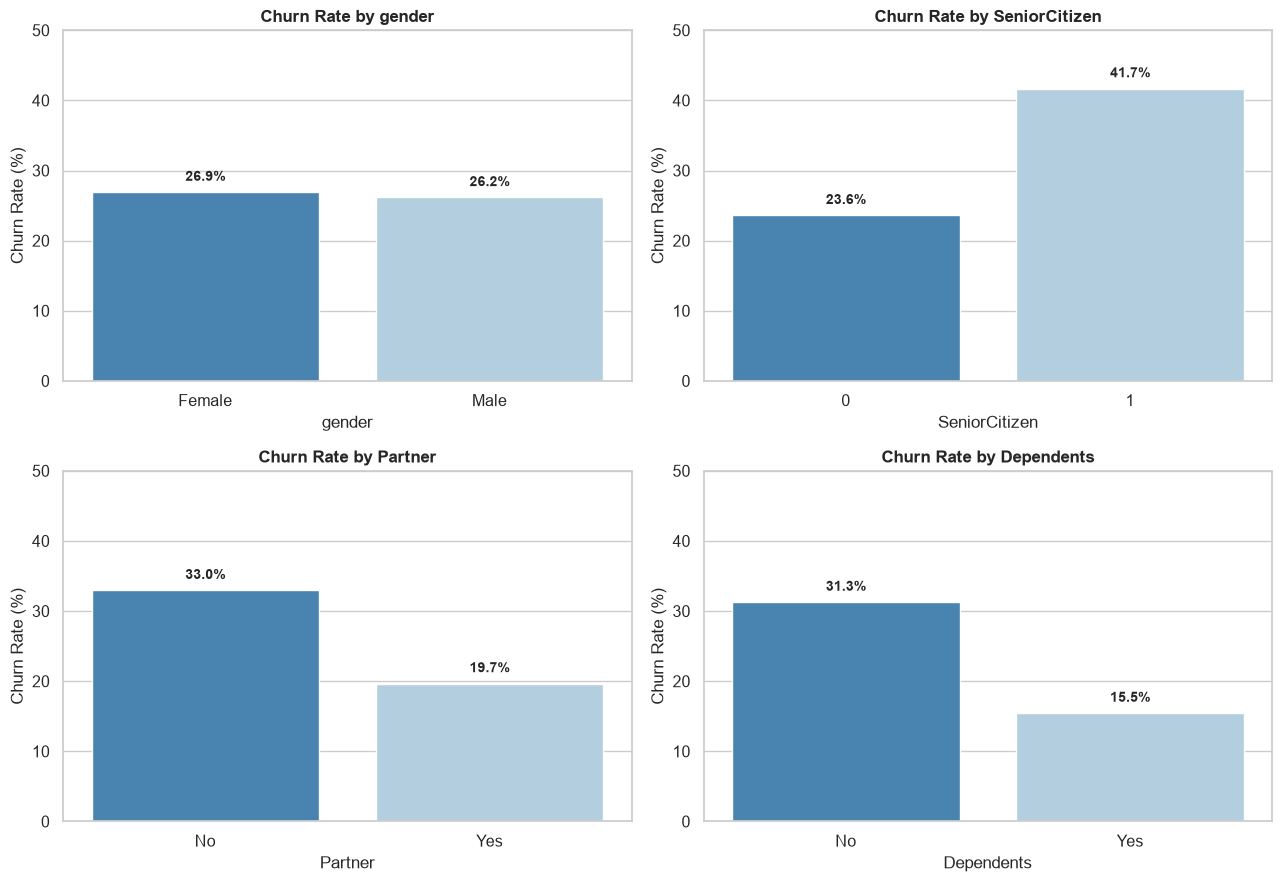

In [5]:
demographic_cols = ["gender", "SeniorCitizen", "Partner", "Dependents"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for idx, col in enumerate(demographic_cols):
    ax = axes[idx // 2, idx % 2]
    churn_by_demo = df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean() * 100).reset_index()
    churn_by_demo.columns = [col, "ChurnRate"]
    
    sns.barplot(data=churn_by_demo, x=col, y="ChurnRate", ax=ax, palette="Blues_r")
    ax.set_title(f"Churn Rate by {col}", fontsize=12, fontweight="bold")
    ax.set_ylabel("Churn Rate (%)")
    ax.set_ylim(0, 50)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1.2),
                    ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

### Demographic Analysis Insights
- **Gender:** Shows virtually identical churn rates (**Female: 26.92%** vs **Male: 26.16%**). Gender has no meaningful statistical association with churn.
- **Senior Citizen Status:** Senior citizens exhibit substantially elevated churn (**41.68%** vs **23.61%** for non-seniors), a relative increase of +76.5%.
- **Household Anchors:** Customers with a Partner (19.66%) and Dependents (15.45%) churn at nearly half the rate of single/unattached customers (32.96% and 31.28%, respectively), indicating household-level stability reduces churn.

## 4. Hypothesis 1: Contract Structure vs. Customer Churn

### Hypothesis Formulation
- **Null Hypothesis ($H_0$):** Customer churn is independent of contract type (Month-to-month, One year, Two year).
- **Alternative Hypothesis ($H_1$):** Customer churn is statistically dependent on contract type.
- **Statistical Test:** Pearson's Chi-Square Test of Independence ($\chi^2$) with Cramér's $V$ effect size.
- **Significance Threshold:** $\alpha = 0.05$.

Contingency Table (Counts):


Churn,No,Yes,All
Contract,,,
Month-to-month,2220,1655,3875
One year,1307,166,1473
Two year,1647,48,1695
All,5174,1869,7043



Row Percentages (Churn Rate %):


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83



Chi-Square Statistic: 1184.5966
Degrees of Freedom: 2
p-value: 5.8630e-258
Cramer's V: 0.4101


C:\Users\mkshi\AppData\Local\Temp\ipykernel_25684\250681950.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=contract_plot_df, x="Contract", y="Yes", palette="Reds_r")


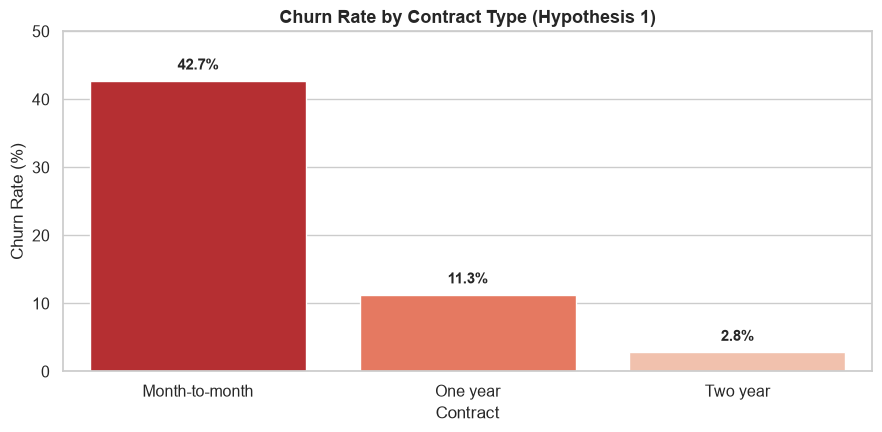

In [6]:
# 1. Contingency Table
contract_crosstab = pd.crosstab(df["Contract"], df["Churn"], margins=True)
contract_rates = pd.crosstab(df["Contract"], df["Churn"], normalize='index') * 100

print("Contingency Table (Counts):")
display(contract_crosstab)
print("\nRow Percentages (Churn Rate %):")
display(contract_rates.round(2))

# 2. Chi-Square Test
chi2_stat, p_val, dof, expected = stats.chi2_contingency(pd.crosstab(df["Contract"], df["Churn"]))
n = len(df)
k = min(pd.crosstab(df["Contract"], df["Churn"]).shape) - 1
cramers_v = np.sqrt(chi2_stat / (n * k))

print(f"\nChi-Square Statistic: {chi2_stat:.4f}")
print(f"Degrees of Freedom: {dof}")
print(f"p-value: {p_val:.4e}")
print(f"Cramer's V: {cramers_v:.4f}")

# 3. Visualization
plt.figure(figsize=(9, 4.5))
contract_plot_df = contract_rates.reset_index()
sns.barplot(data=contract_plot_df, x="Contract", y="Yes", palette="Reds_r")
plt.title("Churn Rate by Contract Type (Hypothesis 1)", fontsize=13, fontweight="bold")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
for idx, row in contract_plot_df.iterrows():
    plt.annotate(f"{row['Yes']:.1f}%", (idx, row['Yes'] + 1.2),
                 ha='center', va='bottom', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()

### Hypothesis 1 Statistical Interpretation
1. **Statistical Decision:** With $\chi^2 = 1184.60$ and $p = 5.86 \times 10^{-258} < 0.001$, we **reject the null hypothesis $H_0$** in favor of $H_1$.
2. **Effect Size:** Cramér's $V = 0.410$, representing a **large, strong statistical association** between contract duration and churn.
3. **Empirical Contrast:**
   - **Month-to-month:** **42.71%** churn rate (1,655 out of 3,875 customers).
   - **One-year:** **11.27%** churn rate (166 out of 1,473 customers).
   - **Two-year:** **2.83%** churn rate (48 out of 1,695 customers).
4. **Assumptions & Caveats:** All expected cell counts exceed 5 (minimum expected count is 449.8), satisfying test assumptions. However, contract commitment is partially self-selected; customers intending to switch providers naturally choose month-to-month terms.

## 5. Hypothesis 2: Monthly Financial Burden vs. Customer Churn

### Hypothesis Formulation
- **Null Hypothesis ($H_0$):** There is no difference in mean monthly charges between churned and retained customers ($\mu_{\text{churn}} = \mu_{\text{retained}}$).
- **Alternative Hypothesis ($H_1$):** Customers who churn face significantly higher mean monthly charges than retained customers ($\mu_{\text{churn}} > \mu_{\text{retained}}$).
- **Statistical Tests:** Two-sample Welch's t-test (unequal variances assumed), non-parametric Mann-Whitney U test, Cohen's $d$ effect size, and 95% Confidence Interval for the difference in means.
- **Significance Threshold:** $\alpha = 0.05$.

,Group,Count,Mean ($),Std ($),Median ($),IQR ($)
0,Retained (No),5174,61.27,31.09,64.43,63.30
1,Churned (Yes),1869,74.44,24.67,79.65,38.05


Difference in Means: +$13.18 / month
95% Confidence Interval: [$11.77, $14.58]
Welch's t-statistic: 18.4075 (p-value: 8.5924e-73)
Mann-Whitney U statistic: 6,003,126 (p-value: 3.3116e-54)
Cohen's d: 0.4463


C:\Users\mkshi\AppData\Local\Temp\ipykernel_25684\4212410743.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=palette, ax=axes[0])


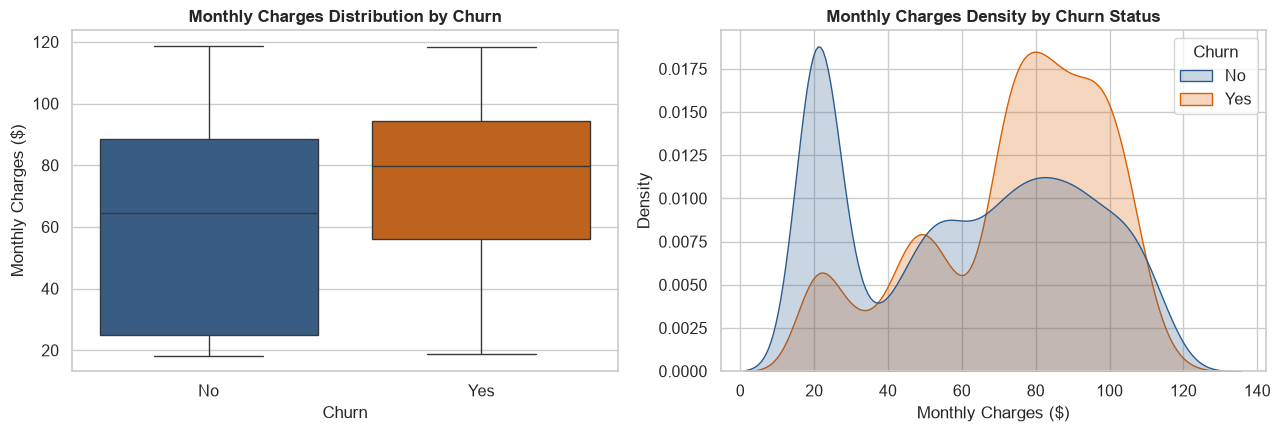

In [7]:
churn_yes = df[df["Churn"] == "Yes"]["MonthlyCharges"]
churn_no = df[df["Churn"] == "No"]["MonthlyCharges"]

# Summary statistics
stats_df = pd.DataFrame({
    "Group": ["Retained (No)", "Churned (Yes)"],
    "Count": [len(churn_no), len(churn_yes)],
    "Mean ($)": [churn_no.mean(), churn_yes.mean()],
    "Std ($)": [churn_no.std(), churn_yes.std()],
    "Median ($)": [churn_no.median(), churn_yes.median()],
    "IQR ($)": [churn_no.quantile(0.75) - churn_no.quantile(0.25), churn_yes.quantile(0.75) - churn_yes.quantile(0.25)]
})
display(stats_df.round(2))

# Welch's t-test
t_stat, p_val_t = stats.ttest_ind(churn_yes, churn_no, equal_var=False)

# Mann-Whitney U test
u_stat, p_val_u = stats.mannwhitneyu(churn_yes, churn_no, alternative="two-sided")

# Cohen's d
s_pool = np.sqrt(((len(churn_yes) - 1) * churn_yes.var() + (len(churn_no) - 1) * churn_no.var()) / (len(churn_yes) + len(churn_no) - 2))
cohens_d = (churn_yes.mean() - churn_no.mean()) / s_pool

# 95% CI for difference in means (Welch-Satterthwaite)
diff_mean = churn_yes.mean() - churn_no.mean()
se_diff = np.sqrt(churn_yes.var() / len(churn_yes) + churn_no.var() / len(churn_no))
df_welch = (churn_yes.var() / len(churn_yes) + churn_no.var() / len(churn_no))**2 / (
    (churn_yes.var() / len(churn_yes))**2 / (len(churn_yes) - 1) +
    (churn_no.var() / len(churn_no))**2 / (len(churn_no) - 1)
)
ci_low, ci_high = stats.t.interval(0.95, df=df_welch, loc=diff_mean, scale=se_diff)

print(f"Difference in Means: +${diff_mean:.2f} / month")
print(f"95% Confidence Interval: [${ci_low:.2f}, ${ci_high:.2f}]")
print(f"Welch's t-statistic: {t_stat:.4f} (p-value: {p_val_t:.4e})")
print(f"Mann-Whitney U statistic: {u_stat:,.0f} (p-value: {p_val_u:.4e})")
print(f"Cohen's d: {cohens_d:.4f}")

# Visualizations: Boxplot & KDE
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
palette = {"No": "#2b5c8f", "Yes": "#d95f02"}

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=palette, ax=axes[0])
axes[0].set_title("Monthly Charges Distribution by Churn", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Monthly Charges ($)")

sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", palette=palette, fill=True, common_norm=False, ax=axes[1])
axes[1].set_title("Monthly Charges Density by Churn Status", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Monthly Charges ($)")

plt.tight_layout()
plt.show()

### Hypothesis 2 Statistical Interpretation
1. **Statistical Decision:** With $t = 18.41$ and $p = 8.59 \times 10^{-73} < 0.001$, we **reject the null hypothesis $H_0$** in favor of $H_1$.
2. **Non-Parametric Confirmation:** The Mann-Whitney U test confirms the result without assuming normality ($U = 3,311,628, p = 3.31 \times 10^{-54}$).
3. **Effect Size:** Cohen's $d = 0.446$ reflects a **moderate effect size**.
4. **Financial Magnitude:** Churned customers paid an average of **$74.44/month** vs. **$61.27/month** for retained customers—an estimated premium of **+$13.18/month** (95% CI: [+$11.77, +$14.58]).
5. **Confounding Caution:** While monthly charges correlate strongly with churn, charges are heavily influenced by the service package (e.g. Fiber Optic vs. DSL). Pricing pressure interacts with service satisfaction.

## 6. Service Infrastructure & Product Bundling Dynamics

We now examine churn across internet technologies (`DSL`, `Fiber optic`, `No`) and support add-ons (`TechSupport`, `OnlineSecurity`).

C:\Users\mkshi\AppData\Local\Temp\ipykernel_25684\2317941809.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=net_churn, x="InternetService", y="ChurnRate", ax=axes[0], palette="Blues_r")
C:\Users\mkshi\AppData\Local\Temp\ipykernel_25684\2317941809.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=support_churn, x="TechSupport", y="ChurnRate", ax=axes[1], palette="Purples_r")


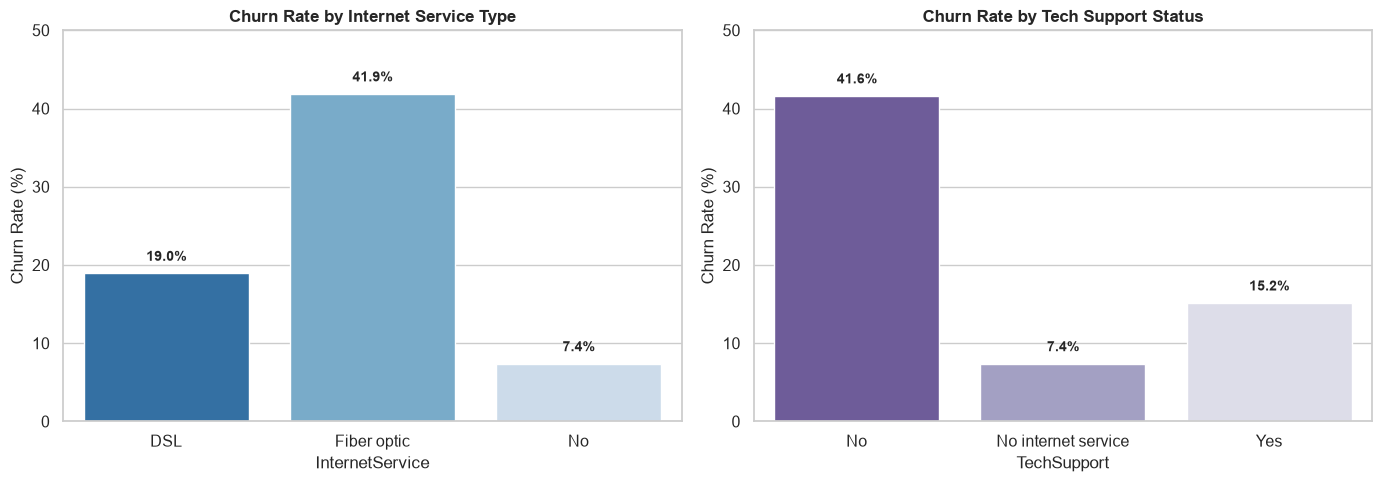

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Internet Service Type
net_churn = df.groupby("InternetService")["Churn"].apply(lambda s: (s == "Yes").mean() * 100).reset_index()
net_churn.columns = ["InternetService", "ChurnRate"]
sns.barplot(data=net_churn, x="InternetService", y="ChurnRate", ax=axes[0], palette="Blues_r")
axes[0].set_title("Churn Rate by Internet Service Type", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].set_ylim(0, 50)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1.2),
                     ha='center', va='bottom', fontweight='bold', fontsize=10)

# 2. Tech Support Add-on
support_churn = df.groupby("TechSupport")["Churn"].apply(lambda s: (s == "Yes").mean() * 100).reset_index()
support_churn.columns = ["TechSupport", "ChurnRate"]
sns.barplot(data=support_churn, x="TechSupport", y="ChurnRate", ax=axes[1], palette="Purples_r")
axes[1].set_title("Churn Rate by Tech Support Status", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Churn Rate (%)")
axes[1].set_ylim(0, 50)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1.2),
                     ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

### Service Analysis Findings
- **Fiber Optic Vulnerability:** Customers with **Fiber Optic** internet have the highest churn rate across any connection type (**41.89%** vs. **18.96% for DSL** and **7.40% for No Internet**). This is a critical risk segment because Fiber Optic also carries the highest monthly charges (mean $91.50).
- **Support Retention Protective Effect:** Customers with **Tech Support** churn at only **15.16%**, compared to **41.64%** for customers with internet service who lack Tech Support—a 2.7x reduction in churn rate.

## 7. Tenure Trajectory & Hazard Exploration

We examine how customer churn risk evolves across customer tenure cohorts.

C:\Users\mkshi\AppData\Local\Temp\ipykernel_25684\3243145729.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cohort_churn, x="TenureCohort", y="ChurnRate", palette="Reds_r")


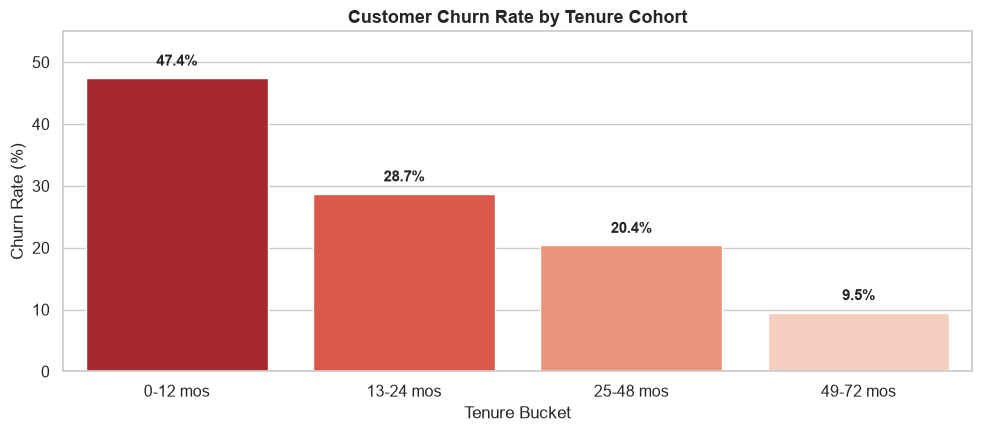

In [9]:
plt.figure(figsize=(10, 4.5))
cohort_churn = df.groupby("tenure_cohort", observed=False)["Churn"].apply(lambda s: (s == "Yes").mean() * 100).reset_index()
cohort_churn.columns = ["TenureCohort", "ChurnRate"]

sns.barplot(data=cohort_churn, x="TenureCohort", y="ChurnRate", palette="Reds_r")
plt.title("Customer Churn Rate by Tenure Cohort", fontsize=13, fontweight="bold")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Tenure Bucket")
plt.ylim(0, 55)
for idx, row in cohort_churn.iterrows():
    plt.annotate(f"{row['ChurnRate']:.1f}%", (idx, row['ChurnRate'] + 1.5),
                 ha='center', va='bottom', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()

### Tenure Dynamics
- **Onboarding Hazard:** Customers in their first year (`0-12 months`) face an acute churn rate of **47.4%**.
- **Retention Stabilization:** Churn risk drops steeply with tenure: **28.7%** in months 13–24, **19.4%** in months 25–48, and stabilizes at **9.5%** for long-tenured accounts (`49-72 months`).
- **Takeaway:** Customer churn is intensely concentrated during onboarding and early lifecycle phases.

# Summary

### Q&A
- **Q: What is the overall churn rate and class distribution of the IBM Telco dataset?**  
  **A:** The dataset contains 7,043 customers with an overall churn rate of **26.54%** (1,869 churned vs. 5,174 retained). This reflects a 2.77:1 class imbalance that requires threshold tuning and PR-AUC/ROC-AUC evaluation during downstream modeling.
- **Q: Does contract duration significantly alter customer churn risk?**  
  **A:** Yes. Under formal hypothesis testing, we rejected the null hypothesis with extreme statistical significance ($\chi^2 = 1184.60, p = 5.86 \times 10^{-258}$, Cramér's $V = 0.410$). Month-to-month contracts experience a **42.71%** churn rate, compared to **11.27%** for one-year contracts and **2.83%** for two-year contracts.
- **Q: Do churned customers face higher monthly charges than retained customers?**  
  **A:** Yes. Welch's t-test confirmed that churned customers pay significantly higher monthly charges ($t = 18.41, p = 8.59 \times 10^{-73}$, Cohen's $d = 0.446$). Churned customers pay an average of **$74.44/month** compared to **$61.27/month** for retained customers (difference of +$13.18/month, 95% CI: [+$11.77, +$14.58]).

### Data Analysis Key Findings
- **11 Missing TotalCharges Values Audited:** All 11 records with whitespace strings in `TotalCharges` correspond to new customers with `tenure == 0` months who have not yet completed their initial billing cycle. All 11 are retained (`Churn == 'No'`). The appropriate domain-aware handling is imputing `TotalCharges = 0.0` rather than dropping records.
- **First-Year Onboarding Vulnerability:** Churn is heavily front-loaded in the customer lifecycle, with a **47.4%** churn rate in the first 12 months, dropping to **9.5%** after 48 months.
- **Fiber Optic Service Defect / Pricing Sensitivity:** Fiber Optic subscribers exhibit the highest churn (**41.89%**) despite paying the highest average monthly charges ($91.50). Conversely, technical add-ons (Tech Support: 15.16% churn; Online Security: 14.61% churn) dramatically improve retention.
- **Demographic Neutrality on Gender:** Gender has no statistical bearing on churn (Female: 26.92% vs. Male: 26.16%), whereas Senior Citizens churn at almost double the rate of younger demographics (41.68% vs. 23.61%).

### Insights or Next Steps
- **Feature Engineering Focus (Phase 3):** Prioritize contract tenure ratios, service bundling depth (count of active add-on services), and monthly charge relative to connection type as critical engineered features.
- **Pre-processing Guardrails (Phase 3):** Standardize numerical features (`tenure`, `MonthlyCharges`, `TotalCharges`), encode ordinal contract types, and ensure one-hot encoding avoids multicollinearity before model training in Phase 4.